# <span style="color:#9947dc">HI-Small — Modelling (transaction scoring)</span>

**What this notebook is for.** The capstone is an agent system that investigates
money-laundering alerts. The model trained here is one of the agent's tools: it scores
every transfer, and the highest scores become the alerts the agent starts from. So the
questions are not "what is the accuracy" but:

1. If we can only alert a fixed small share of transfers, how many laundering transfers do we catch, and how many alerts are wasted?
2. Of the laundering **schemes**, how many get at least one alert (that is all the agent needs to start rebuilding the case)?
3. How much of the result comes from generator artefacts (payment format, the conversion step) rather than behaviour a real bank would see?

**Inputs:** `data/processed/features/` from `03_features.py` (point-in-time features from the
full joined file). **Outputs:** `models/txn_scorer.joblib` (model + threshold for the agent),
`models/test_scores.parquet`, `models/metrics.json`.

**Discipline.** Everything is fitted on **train** (1–6 Sept), every choice (weighting, feature
set, threshold) is made on **validation** (7 Sept), and **test** (8–10 Sept) is scored once, in
section 9. Every metric uses `sample_weight` (all 1 on the full file; inverse inclusion
probabilities if you point this at the 02 sample).

| # | Section |
|---|---|
| 0 | Setup and build check |
| 1 | The data the model sees |
| 2 | Leakage guard |
| 3 | Drift between splits |
| 4 | Baseline: single features |
| 5 | Logistic regression |
| 6 | LightGBM |
| 7 | Model choice on validation |
| 8 | Alert threshold on validation |
| 9 | Test results (scored once) |
| 10 | Who is caught and who is missed |
| 11 | Scheme-level catch rate (what the agent needs) |
| 12 | Why a transfer is flagged |
| 13 | Save for the agent layer |
| 14 | Findings |

## <span style="color:#9947dc">0. Setup</span>

**Why.** One place for every setting. If the feature files are missing, the build scripts
(`03_features.py`, then the independent check `03b_verify_features.py`) are run from here and
the notebook stops if any check fails.

Settings you may want to change:
- `FEATURES_DIR` — `features` (full file, default) or `features_sample` (02 sample, weighted).
- `BURN_IN` — leave out of fitting the first 48 h, when account-history windows are not full yet.
- `TRAIN_NEG_FRACTION` — keep a fraction of training negatives (weights corrected) if fitting is slow.
- `MAIN_BUDGET` — share of transfers we can afford to alert. 0.5% is ~5× the true laundering rate.
- `PRIMARY_SET` — feature set of the model handed to the agent (`all`, `no_format`, `no_generator`).

In [3]:
import json, subprocess, sys, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

ROOT = Path.cwd() if (Path.cwd() / "03_features.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT / "src"))
import features as F
import modeling as M
import evaluation as E

warnings.filterwarnings("ignore", category=UserWarning)
pd.set_option("display.width", 160, "display.max_columns", 30, "display.float_format", "{:,.6g}".format)

# ---------------------------------------------------------------- settings
FEATURES_DIR = ROOT / "data" / "processed" / "features"
MODELS_DIR = ROOT / "models"
BUILD_IF_MISSING = True        # run 03_features.py + 03b_verify_features.py if needed
BURN_IN = True                 # drop rows whose 48 h history window is not full from FITTING
TRAIN_NEG_FRACTION = 1.0       # e.g. 0.25 to fit faster (negatives re-weighted)
SEED = 42
BUDGETS = (0.001, 0.0025, 0.005, 0.01, 0.02)
MAIN_BUDGET = 0.005            # alert the top 0.5% of transfers
PRIMARY_SET = "all"            # model handed to the agent
BOOTSTRAP_B = 100              # resamples of sender accounts for confidence intervals
TEST_DAYS = 3                  # 8-10 Sept

PURPLE, DARK, GREY = "#9947dc", "#6b21a8", "#9ca3af"
SET_COLOURS = {"all": PURPLE, "no_format": "#0ea5e9", "no_generator": "#f59e0b"}
print("project folder:", ROOT)
print("feature folder:", FEATURES_DIR)

project folder: c:\Users\almad\Documents\3rd year\1st semester\ProjFinalCurso\Project\Capstone-Project\MoneyLaundering
feature folder: c:\Users\almad\Documents\3rd year\1st semester\ProjFinalCurso\Project\Capstone-Project\MoneyLaundering\data\processed\features


In [5]:
def run(script, *args):
    # stream a pipeline script's output; stop on failure or on 'X / Y checks passed' with X != Y
    print(f"$ python {script} {' '.join(args)}")
    p = subprocess.Popen([sys.executable, str(ROOT / script), *args], cwd=ROOT,
                         stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True)
    lines = []
    for line in p.stdout:
        print(line, end=""); lines.append(line)
    if p.wait() != 0:
        raise RuntimeError(f"{script} failed (exit {p.returncode})")
    for line in lines:
        if "checks passed" in line:
            a, b = line.split("checks passed")[0].split("/")
            if int(a) != int(b):
                raise RuntimeError(f"{script}: {line.strip()}")

needed = [FEATURES_DIR / f"{s}_{k}.parquet" for s in M.SPLITS for k in ("features", "meta")]
if all(p.exists() for p in needed):
    print("feature files found - nothing to build")
elif BUILD_IF_MISSING:
    t0 = time.time()
    run("03_features.py")
    run("03b_verify_features.py")
    print(f"built in {time.time() - t0:.0f} s")
else:
    raise FileNotFoundError("feature files missing - run 03_features.py")

report = json.loads((FEATURES_DIR / "build_report.json").read_text())
print({k: report[k] for k in ("scored_rows", "scored_positives", "lookback_hours", "burn_in_rows", "n_hubs")})
print("build checks:", sum(report["checks"].values()), "/", len(report["checks"]), "passed")

$ python 03_features.py 
[   0.1s] reading hi_small_joined.parquet (rows before 2022-09-11)...
[  68.5s] base: 5,077,228 rows kept, 1,108 residue rows dropped, 590,819 self-transfers, 4,522 positives
[  69.1s] FX table: 15 currencies, max spread within a pair 0.9409%
[  70.8s] hubs (>= 500 counterparties, train dates): 15
[ 109.3s] cumulative event tables built
[ 332.4s] 16 point-in-time lookups done
[ 405.7s] feature table assembled

================ CHECKS ================
[PASS] scored rows = kept rows minus self-transfers: 4,486,409 vs 4,486,409
[PASS] row key unique: 0 duplicate keys
[PASS] no NULL / NaN in numeric features: []
[PASS] every row has a split: 0
[PASS] each attempt in one split: 0 attempts split
[PASS] split row counts add up: {'train': (2695998, 1989), 'val': (472186, 323), 'test': (1318225, 2202)}
[PASS] FX pairs consistent (< 2% spread): 0.9409%
7 / 7 checks passed

split        rows   positives   rate      weighted rate
train   2,695,998      1,989   0.0738%   0.

## <span style="color:#9947dc">1. The data the model sees</span>

**Why.** Before fitting anything: how many rows and positives each split has, and what the
true (weighted) laundering rate is. PR-AUC only means something next to the prevalence of the
split it was measured on — a PR-AUC of 0.01 is 10× better than random at 0.1% prevalence.

**How.** Load the three splits. Rows of a scheme that crosses a split boundary were moved to the
split of the scheme's last row (`scheme_moved`) — so test has extra positives from schemes that
started earlier. Self-transfers are not scored (they are bookings, not payments) and are already
gone. The burn-in rows (first 48 h) stay in the data but are not used to fit.

**What to check.** Test prevalence is expected to be higher than train (moved schemes);
unexplained positives (no `Attempt ID`) are a different population — EDA v2 found none after
10 Sept, so their share per split matters for the breakdown in section 10.

In [6]:
splits = M.load_splits(FEATURES_DIR)
rows = []
for name, s in splits.items():
    m = s.meta
    rows.append({
        "split": name, "days": f"{m.Timestamp.min():%d %b} - {m.Timestamp.max():%d %b}",
        "rows": len(s), "positives": int(s.y.sum()),
        "rate": s.y.mean(), "weighted_rate": E.prevalence(s.y, s.w),
        "explained_pos": int((m.explained & (s.y == 1)).sum()),
        "unexplained_pos": int((~m.explained & (s.y == 1)).sum()),
        "moved_rows": int(m.scheme_moved.sum()),
        "burn_in_rows": int((~m.history_complete).sum()),
        "attempts": m["Attempt ID"].nunique(),
    })
overview = pd.DataFrame(rows).set_index("split")
display(overview)

train_fit = M.fit_rows(splits["train"], burn_in=BURN_IN)
if TRAIN_NEG_FRACTION < 1:
    train_fit = M.downsample_negatives(train_fit, TRAIN_NEG_FRACTION, seed=SEED)
val, test = splits["val"], splits["test"]
print(f"rows used to fit: {len(train_fit):,} ({int(train_fit.y.sum()):,} positives) "
      f"of {len(splits['train']):,} train rows; weighted rate {E.prevalence(train_fit.y, train_fit.w):.4%}")

,days,rows,positives,rate,weighted_rate,explained_pos,unexplained_pos,moved_rows,burn_in_rows,attempts
split,,,,,,,,,,
train,01 Sep - 06 Sep,2695998,1989,0.00073776,0.00073776,771,1218,0,1346461,124
val,03 Sep - 07 Sep,472186,323,0.000684052,0.000684052,155,168,94,0,31
test,01 Sep - 10 Sep,1318225,2202,0.00167043,0.00167043,1620,582,709,17,208


rows used to fit: 1,349,537 (1,277 positives) of 2,695,998 train rows; weighted rate 0.0946%


## <span style="color:#9947dc">2. Leakage guard</span>

**Why.** The EDA proved several columns predict the label perfectly because they come from the
patterns file or the sampling (`Attempt ID`, `Pattern Type`, `scheme_truncated`, `weight`, seeds…),
and IDs let a model memorise accounts. None may reach a model.

**How.** The X tables contain only the feature list from `src/features.py`; this cell asserts that
no column of the leak list is present and prints the features by group.

In [7]:
for name, s in splits.items():
    M.assert_no_leak(s.X)
print("no leak / ID columns in X  ✓\n")
groups = {"counts (48 h / 24 h / 60 min windows)": F.COUNT_FEATURES, "flags": F.FLAG_FEATURES,
          "amount": F.AMOUNT_FEATURES, "categorical": F.CATEGORICAL_FEATURES}
for g, cols in groups.items():
    print(f"{g:<40} {len(cols):>2}  {', '.join(cols)}")
print("\nfeature sets:", {k: len(v) for k, v in M.FEATURE_SETS.items()})
print("dropped from 'no_format':   ", F.FORMAT_FEATURES)
print("dropped from 'no_generator':", F.GENERATOR_FEATURES)

no leak / ID columns in X  ✓

counts (48 h / 24 h / 60 min windows)     9  pair_prev_48h, snd_sent_48h, snd_recv_48h, snd_sent_24h, snd_sent_60m, rcv_recv_48h, rcv_sent_48h, rcv_recv_24h, rcv_recv_60m
flags                                    11  new_pair_48h, reverse_pair_48h, snd_quiet_48h, rcv_quiet_48h, conversion_before, snd_hub, rcv_hub, cross_border, cross_bank, same_entity, currency_changes
amount                                    1  log_amount_usd
categorical                               6  payment_format, payment_currency, country_from, country_to, etype_from, etype_to

feature sets: {'all': 27, 'no_format': 26, 'no_generator': 25}
dropped from 'no_format':    ['payment_format']
dropped from 'no_generator': ['payment_format', 'conversion_before']


## <span style="color:#9947dc">3. Drift between splits</span>

**Why.** A time split only tests generalisation if the features mean the same thing in every
split. Counts "since the start of the data" fail this: they grow with the calendar, so test rows
look busier than train rows for no reason. That is why `03_features.py` uses fixed 48 h windows.
This cell checks it.

**How.** Population stability index (PSI) of each feature, train vs validation and train vs test,
weighted. Numeric features are binned at train quantiles. Rule of thumb: below 0.1 stable,
0.1–0.25 moderate, above 0.25 a big shift.

**What to check.** Nothing should be flagged `big`. If a feature is, find out why before trusting
any test number that depends on it.

In [8]:
numeric = F.COUNT_FEATURES + F.FLAG_FEATURES + F.AMOUNT_FEATURES
drift = E.psi_table(train_fit.X, train_fit.w, {"val": (val.X, val.w), "test": (test.X, test.w)},
                    numeric, F.CATEGORICAL_FEATURES)
display(drift)
print(drift["flag"].value_counts().to_string())

,val,test,max_psi,flag
feature,,,,
rcv_recv_48h,0.30304,0.13659,0.30304,big
pair_prev_48h,0.298795,0.0742883,0.298795,big
snd_sent_48h,0.134318,0.0824492,0.134318,moderate
snd_recv_48h,0.0721802,0.112101,0.112101,moderate
rcv_sent_48h,0.0539512,0.0343614,0.0539512,stable
snd_sent_24h,0.0506026,0.031655,0.0506026,stable
rcv_recv_24h,0.0453847,0.0394508,0.0453847,stable
log_amount_usd,0.00158145,0.003013,0.003013,stable
snd_sent_60m,0.00161778,0.00187216,0.00187216,stable


flag
stable      23
moderate     2
big          2


## <span style="color:#9947dc">4. Baseline: single features</span>

**Why.** A model is only worth having if it beats the best single column. This is also the
honest version of the EDA's "single-feature AP" ranking, now on point-in-time features and on
a split the direction was not chosen on.

**How.** Each numeric feature is used alone as a score. Whether "higher" or "lower" is riskier is
decided on train; PR-AUC is then measured on validation. Lift = PR-AUC ÷ prevalence.
The best one becomes the `rule` model.

In [9]:
single = M.single_feature_table(train_fit, val)
display(single)
rule = M.fit_rule(train_fit, val)
print(f"rule model: score = {'+' if rule.sign > 0 else '-'}{rule.feature}")

,feature,direction,train_ap,train_lift,val_ap,val_lift
0,pair_prev_48h,lower,0.00398276,4.20899,0.00755245,11.0407
1,new_pair_48h,higher,0.00380542,4.02158,0.00723296,10.5737
2,snd_sent_48h,lower,0.0045379,4.79566,0.00672143,9.8259
3,reverse_pair_48h,higher,0.00633862,6.69867,0.0066533,9.7263
4,rcv_recv_48h,lower,0.001814,1.91704,0.00426885,6.24052
5,conversion_before,higher,0.00367391,3.88259,0.00340809,4.98221
6,snd_quiet_48h,higher,0.00249707,2.63891,0.00248537,3.6333
7,rcv_quiet_48h,higher,0.00139869,1.47813,0.00243196,3.55522
8,snd_sent_24h,lower,0.00269401,2.84704,0.00194412,2.84207
9,log_amount_usd,higher,0.00245022,2.5894,0.00116098,1.69721


rule model: score = -pair_prev_48h


## <span style="color:#9947dc">5. Logistic regression</span>

**Why.** A transparent model whose coefficients can be read in the report and checked against
the EDA. It needs more preparation than trees:
- counts → `log1p` then standardised (they are heavy-tailed);
- amount → 10 quantile buckets, because risk by amount goes up and then down again (EDA v2);
- categories → one-hot, levels with fewer than 100 train rows grouped as "infrequent";
- strongly correlated numeric pairs (Spearman > 0.85 on train) → one of each dropped;
- `class_weight="balanced"` instead of over-sampling.

**How.** Fit once per feature set, measure PR-AUC on validation.

In [10]:
drop, pairs = M.correlated_to_drop(train_fit.X, [f for f in F.COUNT_FEATURES + F.FLAG_FEATURES])
print("most correlated numeric pairs on train:")
display(pairs.head(8))
print("dropped for logistic regression:", drop)

logreg = {}
for fs, cols in M.FEATURE_SETS.items():
    t0 = time.time()
    logreg[fs] = M.fit_logreg(train_fit, cols, drop=drop, seed=SEED)
    ap = E.headline(val.y, logreg[fs].predict_score(val.X), val.w)["pr_auc"]
    print(f"logreg / {fs:<13} val PR-AUC {ap:.4f}   ({time.time() - t0:.0f} s)")

most correlated numeric pairs on train:


,a,b,abs_spearman
0,snd_sent_48h,snd_sent_24h,0.889831
1,pair_prev_48h,rcv_recv_48h,0.690326
2,rcv_recv_48h,rcv_recv_24h,0.687648
3,pair_prev_48h,new_pair_48h,0.649119
4,snd_sent_60m,rcv_recv_60m,0.61262
5,snd_sent_24h,snd_sent_60m,0.577184
6,snd_sent_60m,snd_hub,0.560447
7,snd_sent_24h,snd_hub,0.529818


dropped for logistic regression: ['snd_sent_24h']
logreg / all           val PR-AUC 0.1363   (59 s)
logreg / no_format     val PR-AUC 0.0818   (55 s)
logreg / no_generator  val PR-AUC 0.0505   (58 s)


In [11]:
coef = M.logreg_coefficients(logreg["all"])
display(coef.head(15))

,term,coef
0,flags__snd_hub,10.6518
1,flags__reverse_pair_48h,4.42368
2,cats__payment_format_ACH,4.30791
3,cats__payment_format_Wire,-4.11634
4,cats__country_to_Croatia,-3.51323
5,cats__country_to_Slovenia,-3.08038
6,cats__payment_currency_Yen,-2.65609
7,flags__conversion_before,2.65558
8,cats__etype_to_Individual,-2.50788
9,flags__currency_changes,-2.41797


## <span style="color:#9947dc">6. LightGBM</span>

**Why.** Gradient-boosted trees handle non-monotonic effects (amount), interactions (e.g. new
pair × conversion) and categories natively, with no scaling. They are the expected best model.

**How.**
1. Class weighting is the one setting that matters most at ~1:1000. Full re-weighting
   (`scale_pos_weight` = negatives ÷ positives) tends to overshoot: leaves become nearly pure
   positive after a few trees and validation PR-AUC peaks early. We compare full, square root
   and none **on validation** and keep the best.
2. Then one model per feature set, each early-stopped on validation PR-AUC.

In [12]:
spw_rows, lgbm_spw = [], {}
for spw in ("full", "sqrt", 1.0):
    t0 = time.time()
    mdl = M.fit_lgbm(train_fit, val, M.FEATURE_SETS["all"], spw=spw, seed=SEED)
    ap = E.headline(val.y, mdl.predict_score(val.X), val.w)["pr_auc"]
    spw_rows.append({"scale_pos_weight": spw, "value": mdl.booster.get_params()["scale_pos_weight"],
                     "best_iteration": mdl.best_iteration, "val_pr_auc": ap, "seconds": time.time() - t0})
    lgbm_spw[spw] = mdl
spw_table = pd.DataFrame(spw_rows)
display(spw_table)
BEST_SPW = spw_table.sort_values("val_pr_auc", ascending=False).iloc[0]["scale_pos_weight"]
print("chosen on validation:", BEST_SPW)

,scale_pos_weight,value,best_iteration,val_pr_auc,seconds
0,full,"1,055.8",1331,0.0122386,263.874
1,sqrt,32.4931,261,0.0868285,68.2273
2,1,1,83,0.433443,40.8766


chosen on validation: 1.0


lgbm / no_format     best iteration   125  (44 s)
lgbm / no_generator  best iteration   133  (44 s)


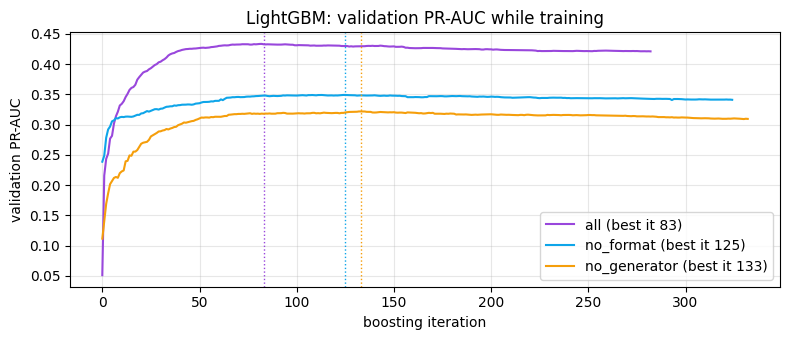

In [13]:
lgbm = {"all": lgbm_spw[BEST_SPW]}
for fs in ("no_format", "no_generator"):
    t0 = time.time()
    lgbm[fs] = M.fit_lgbm(train_fit, val, M.FEATURE_SETS[fs], spw=BEST_SPW, seed=SEED)
    print(f"lgbm / {fs:<13} best iteration {lgbm[fs].best_iteration:>5}  ({time.time() - t0:.0f} s)")

fig, ax = plt.subplots(figsize=(8, 3.5))
for fs, mdl in lgbm.items():
    curve = mdl.history["val"]["average_precision"]
    ax.plot(curve, color=SET_COLOURS[fs], label=f"{fs} (best it {mdl.best_iteration})")
    ax.axvline(mdl.best_iteration, color=SET_COLOURS[fs], ls=":", lw=1)
ax.set_xlabel("boosting iteration"); ax.set_ylabel("validation PR-AUC")
ax.set_title("LightGBM: validation PR-AUC while training"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.show()

## <span style="color:#9947dc">7. Model choice on validation</span>

**Why.** Pick the model for the agent without looking at test.

**How.** Every model × feature set scored on validation. The model handed to the agent is the
best one **within `PRIMARY_SET`**; the other feature sets are reported next to it so the report
can say how much the generator artefacts are worth.

In [14]:
models = {("rule", "all"): rule}
models.update({("logreg", fs): m for fs, m in logreg.items()})
models.update({("lgbm", fs): m for fs, m in lgbm.items()})

val_scores = {k: m.predict_score(val.X) for k, m in models.items()}
val_table = pd.DataFrame([{"model": k[0], "features": k[1], **E.headline(val.y, s, val.w)}
                          for k, s in val_scores.items()]).sort_values("pr_auc", ascending=False)
display(val_table.reset_index(drop=True))

cand = val_table[val_table.features == PRIMARY_SET].iloc[0]
CHOSEN = (cand["model"], cand["features"])
chosen = models[CHOSEN]
print(f"chosen for the agent: {CHOSEN[0]} / {CHOSEN[1]}  (validation PR-AUC {cand['pr_auc']:.4f})")

,model,features,rows,positives,prevalence,pr_auc,pr_auc_lift,roc_auc
0,lgbm,all,472186,323,0.000684052,0.433443,633.64,0.979953
1,lgbm,no_format,472186,323,0.000684052,0.349092,510.329,0.973528
2,lgbm,no_generator,472186,323,0.000684052,0.321842,470.493,0.972365
3,logreg,all,472186,323,0.000684052,0.13628,199.224,0.976492
4,logreg,no_format,472186,323,0.000684052,0.0818004,119.582,0.966541
5,logreg,no_generator,472186,323,0.000684052,0.0505163,73.8485,0.964276
6,rule,all,472186,323,0.000684052,0.0338474,49.4808,0.864571


chosen for the agent: lgbm / all  (validation PR-AUC 0.4334)


## <span style="color:#9947dc">8. Alert threshold on validation</span>

**Why.** In production the score is turned into alerts with a fixed threshold. The threshold must
come from data the evaluation does not use, so it is set on validation for each alert budget and
carried to test unchanged.

**How.** For each budget, the threshold is the score above which that share of validation
transfers fall. The table shows what that threshold achieves on validation itself (precision,
recall, alerts per day); section 9 shows what it achieves on test.

In [15]:
s_val = val_scores[CHOSEN]
val_budget = E.budget_table(val.y, s_val, val.w, BUDGETS, n_days=1)
display(val_budget[["budget", "threshold", "alerts", "alerts_per_day", "precision", "recall", "lift"]])
THRESHOLD = E.threshold_for_budget(s_val, val.w, MAIN_BUDGET)
print(f"threshold for the {MAIN_BUDGET:.2%} budget: {THRESHOLD:.6g}")

,budget,threshold,alerts,alerts_per_day,precision,recall,lift
0,0.001,0.0469788,473,473,0.306554,0.448916,448.144
1,0.0025,0.0287815,1181,"1,181",0.140559,0.513932,205.48
2,0.005,0.0178169,2361,"2,361",0.0808979,0.591331,118.263
3,0.01,0.00898955,4722,"4,722",0.0474375,0.693498,69.3478
4,0.02,0.00275182,9444,"9,444",0.0262601,0.767802,38.389


threshold for the 0.50% budget: 0.0178169


## <span style="color:#9947dc">9. Test results (scored once)</span>

**Why.** The only numbers that go in the report as performance.

**How.** Every model scored on test once. PR-AUC next to test prevalence; then, for the chosen
model, precision and recall at each budget **using the validation thresholds**; then 95%
intervals by resampling sender accounts (rows of one account are not independent, so resampling
rows would make the intervals too narrow).

**What to check.** The gap between `all` and `no_generator` is how much of the score comes from
the generator's mechanics (payment format and the conversion step). If it is large, the report
must say the model partly learns the simulator.

In [16]:
test_scores = {k: m.predict_score(test.X) for k, m in models.items()}
test_table = pd.DataFrame([{"model": k[0], "features": k[1], **E.headline(test.y, s, test.w)}
                           for k, s in test_scores.items()]).sort_values("pr_auc", ascending=False)
display(test_table.reset_index(drop=True))

s_test = test_scores[CHOSEN]
test_budget = E.budget_table(test.y, s_test, test.w, BUDGETS, thresholds_from=(s_val, val.w), n_days=TEST_DAYS)
print(f"\n{CHOSEN[0]} / {CHOSEN[1]} on test, thresholds from validation:")
display(test_budget[["budget", "threshold", "alerts", "alert_rate", "alerts_per_day", "precision", "recall", "lift"]])

,model,features,rows,positives,prevalence,pr_auc,pr_auc_lift,roc_auc
0,lgbm,all,1318225,2202,0.00167043,0.611463,366.052,0.988588
1,lgbm,no_format,1318225,2202,0.00167043,0.425125,254.5,0.972858
2,lgbm,no_generator,1318225,2202,0.00167043,0.324582,194.311,0.973851
3,logreg,all,1318225,2202,0.00167043,0.264757,158.497,0.982591
4,logreg,no_format,1318225,2202,0.00167043,0.0732931,43.8768,0.958227
5,logreg,no_generator,1318225,2202,0.00167043,0.034708,20.7779,0.948436
6,rule,all,1318225,2202,0.00167043,0.0312345,18.6985,0.926194



lgbm / all on test, thresholds from validation:


,budget,threshold,alerts,alert_rate,alerts_per_day,precision,recall,lift
0,0.001,0.0469788,3665,0.00278025,"1,221.67",0.386903,0.64396,231.619
1,0.0025,0.0287815,7216,0.00547403,"2,405.33",0.215771,0.707084,129.171
2,0.005,0.0178169,13087,0.00992774,"4,362.33",0.129594,0.770209,77.5815
3,0.01,0.00898955,24050,0.0182442,"8,016.67",0.0771726,0.84287,46.1993
4,0.02,0.00275182,48080,0.0364733,"16,026.7",0.0414517,0.905086,24.815


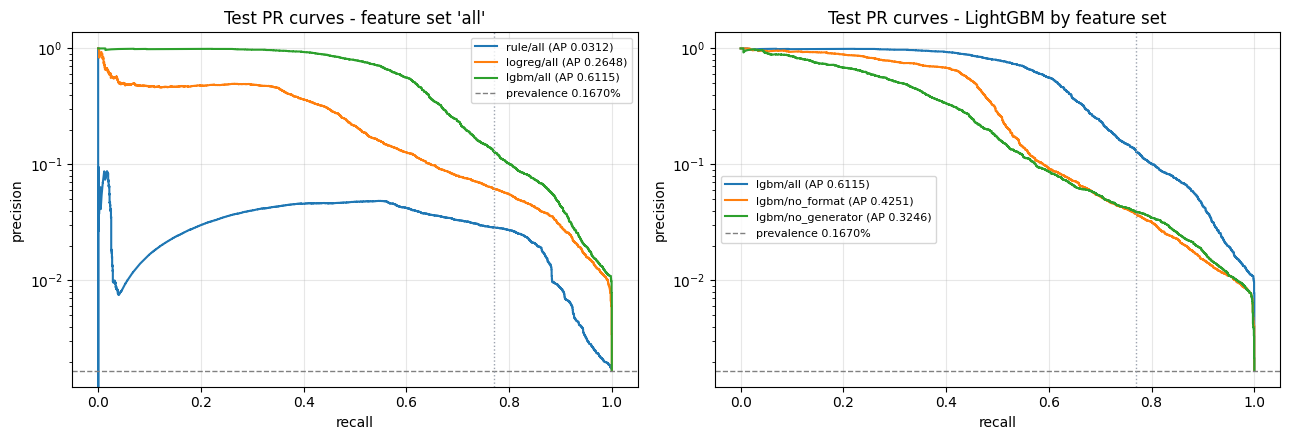

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
E.plot_pr(axes[0], {f"{k[0]}/{k[1]}": s for k, s in test_scores.items() if k[1] == PRIMARY_SET},
          test.y, test.w, title=f"Test PR curves - feature set '{PRIMARY_SET}'")
E.plot_pr(axes[1], {f"lgbm/{fs}": test_scores[("lgbm", fs)] for fs in lgbm},
          test.y, test.w, title="Test PR curves - LightGBM by feature set")
for ax in axes:
    ax.axvline(test_budget.loc[test_budget.budget == MAIN_BUDGET, "recall"].iloc[0],
               color=GREY, ls=":", lw=1)
plt.tight_layout(); plt.show()

In [18]:
groups = test.meta["acct_from"].to_numpy()
ci = [
    {"model": f"{CHOSEN[0]}/{CHOSEN[1]}", **E.cluster_bootstrap(test.y, s_test, test.w, groups, "pr_auc", BOOTSTRAP_B, SEED)},
    {"model": f"{CHOSEN[0]}/{CHOSEN[1]}", **E.cluster_bootstrap(test.y, s_test, test.w, groups, "recall", BOOTSTRAP_B, SEED, THRESHOLD)},
    {"model": f"{CHOSEN[0]}/{CHOSEN[1]}", **E.cluster_bootstrap(test.y, s_test, test.w, groups, "precision", BOOTSTRAP_B, SEED, THRESHOLD)},
]
if CHOSEN[1] != "no_generator" and ("lgbm", "no_generator") in test_scores:
    ci.append({"model": "lgbm/no_generator", **E.cluster_bootstrap(
        test.y, test_scores[("lgbm", "no_generator")], test.w, groups, "pr_auc", BOOTSTRAP_B, SEED)})
ci_table = pd.DataFrame(ci)
print(f"95% intervals, {BOOTSTRAP_B} resamples of sender accounts; recall / precision at the {MAIN_BUDGET:.2%} budget")
display(ci_table)

95% intervals, 100 resamples of sender accounts; recall / precision at the 0.50% budget


,model,metric,B,mean,lo,hi
0,lgbm/all,pr_auc,100,0.608632,0.559375,0.646792
1,lgbm/all,recall,100,0.767831,0.710997,0.817094
2,lgbm/all,precision,100,0.129491,0.119897,0.140571
3,lgbm/no_generator,pr_auc,100,0.323148,0.294011,0.34937


## <span style="color:#9947dc">10. Who is caught and who is missed</span>

**Why.** One recall number hides very different groups. EDA v2 showed the 1,968 unexplained
positives (no scheme in the patterns file) look nothing like scheme transfers — 99.97% of
explained ones are ACH — and the plan says to report them separately. Payment format and
pattern type show whether the model only finds one kind of laundering.

**How.** At the main budget with the validation threshold: recall per group on test, and alert
volume and precision per test day (a stable system should not swing much day to day).

In [19]:
alert = s_test >= THRESHOLD
print(f"alerts on test: {alert.sum():,} of {len(alert):,} transfers\n")
for col in ("explained", "Pattern Type", "Payment Format"):
    print(f"recall by {col}:")
    display(E.recall_breakdown(test.meta, alert, col))

per_day = (pd.DataFrame({"day": test.meta["Timestamp"].dt.date, "alert": alert, "y": test.y, "w": test.w})
           .assign(tp=lambda d: d.alert & (d.y == 1))
           .groupby("day").agg(rows=("y", "size"), positives=("y", "sum"),
                                alerts=("alert", "sum"), true_positives=("tp", "sum")))
per_day["precision"] = per_day.true_positives / per_day.alerts
per_day["recall"] = per_day.true_positives / per_day.positives
print("per test day (rows moved from earlier schemes are counted on their own date):")
display(per_day)

alerts on test: 13,087 of 1,318,225 transfers

recall by explained:


c:\Users\almad\Documents\3rd year\1st semester\ProjFinalCurso\Project\Capstone-Project\MoneyLaundering\src\evaluation.py:88: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  d = pd.DataFrame({by: meta.loc[pos, by].astype("object").fillna("(none)").to_numpy(),


,positives,caught,recall
explained,,,
True,1620,1520,0.938272
False,582,176,0.302405


recall by Pattern Type:


,positives,caught,recall
Pattern Type,,,
(none),582,176,0.302405
GATHER-SCATTER,408,391,0.958333
SCATTER-GATHER,323,308,0.95356
STACK,297,269,0.905724
FAN-IN,149,141,0.946309
CYCLE,145,133,0.917241
FAN-OUT,137,129,0.941606
RANDOM,81,76,0.938272
BIPARTITE,80,73,0.9125


recall by Payment Format:


,positives,caught,recall
Payment Format,,,
ACH,2006,1696,0.845464
Cheque,90,0,0
Credit Card,57,0,0
Cash,30,0,0
Bitcoin,19,0,0


per test day (rows moved from earlier schemes are counted on their own date):


,rows,positives,alerts,true_positives,precision,recall
day,,,,,,
2022-09-01,4,4,4,4,1,1
2022-09-02,13,13,13,13,1,1
2022-09-03,24,24,24,24,1,1
2022-09-04,56,56,54,54,1,0.964286
2022-09-05,138,138,131,131,1,0.949275
2022-09-06,206,206,193,193,1,0.936893
2022-09-07,268,268,246,246,1,0.91791
2022-09-08,472363,539,2664,379,0.142267,0.703154
2022-09-09,641219,513,7016,324,0.0461802,0.631579


## <span style="color:#9947dc">11. Scheme-level catch rate (what the agent needs)</span>

**Why.** The agent does not need every laundering transfer to be alerted: one alert is enough
to start, and the agent's tools (DuckDB over the full joined file) walk the money from there.
So the number that matters for the system is **how many schemes get at least one alert**, and
how early in the scheme the first alert comes.

**How.** For each laundering attempt in test: rows, rows alerted, caught (≥ 1 alert), and the
position of the first alerted transfer in the scheme (0 = the very first transfer). Truncated
schemes (part of them after 10 Sept) are shown separately — only complete schemes can be used
to score the agent's case reconstruction.

schemes  caught  row_recall  median_first_alert_step  catch_rate
pattern        truncated                                                                  
BIPARTITE      False           12      12    0.887097                        0           1
               True             5       5           1                        0           1
CYCLE          False           19      19    0.941176                        0           1
               True            11      11    0.860465                        0           1
FAN-IN         False           11      11     0.94382                        0           1
               True            13      13        0.95                        0           1
FAN-OUT        False           12      12      0.9625                        0           1
               True            11      11    0.912281                        0           1
GATHER-SCATTER False           13      13    0.981308                        0           1
               True            27      26     0.93299                        0    0.962963
RANDOM         False           12      11    0.925926                        0    0.916667
               True             9       8    0.962963                        0    0.888889
SCATTER-GATHER False           13      13    0.954082                        0           1
               True            16      16    0.952756                        0           1
STACK          False           15      15    0.909574                        0           1
               True             9       9    0.899083                        0           1

complete schemes in test: 107, caught: 106 (99.1%); truncated: 101, caught: 99
row-level recall inside complete schemes: 94.4%
median position of the first alert in caught complete schemes: 0


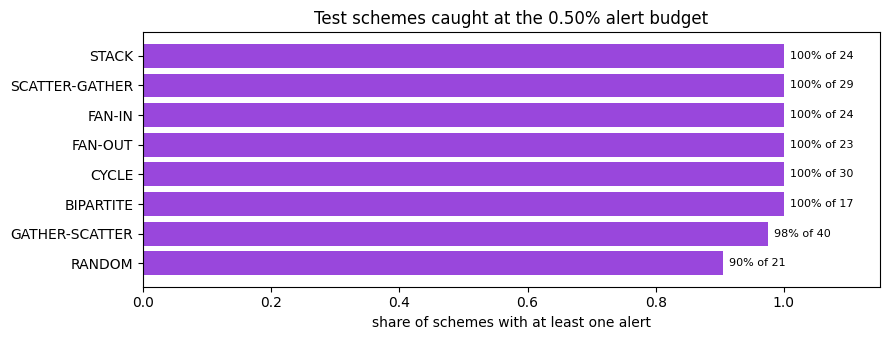

In [20]:
schemes = E.scheme_catch(test.meta, alert)
summary = E.scheme_summary(schemes)
display(summary)
complete = schemes[~schemes.truncated]
print(f"complete schemes in test: {len(complete)}, caught: {int(complete.caught.sum())} "
      f"({complete.caught.mean():.1%}); truncated: {int(schemes.truncated.sum())}, "
      f"caught: {int(schemes[schemes.truncated].caught.sum())}")
print(f"row-level recall inside complete schemes: {complete.rows_alerted.sum() / complete.rows.sum():.1%}")
print(f"median position of the first alert in caught complete schemes: "
      f"{complete.loc[complete.caught, 'first_alert_step'].median():.0f}")

fig, ax = plt.subplots(figsize=(9, 3.5))
by_type = schemes.groupby("pattern")["caught"].agg(["mean", "size"]).sort_values("mean")
ax.barh(by_type.index, by_type["mean"], color=PURPLE)
for i, (m, n) in enumerate(zip(by_type["mean"], by_type["size"])):
    ax.text(m + 0.01, i, f"{m:.0%} of {n}", va="center", fontsize=8)
ax.set_xlim(0, 1.15); ax.set_xlabel("share of schemes with at least one alert")
ax.set_title(f"Test schemes caught at the {MAIN_BUDGET:.2%} alert budget"); plt.tight_layout(); plt.show()

## <span style="color:#9947dc">12. Why a transfer is flagged</span>

**Why.** The agent has to explain each alert to an investigator, and the report has to show the
model uses the signals the EDA found rather than something odd.

**How.** For LightGBM: share of total split gain per feature, and mean absolute SHAP value
(exact TreeSHAP, built into LightGBM) on a sample of test alerts. Then three example alerts with
their top reasons, as the agent tool will return them.

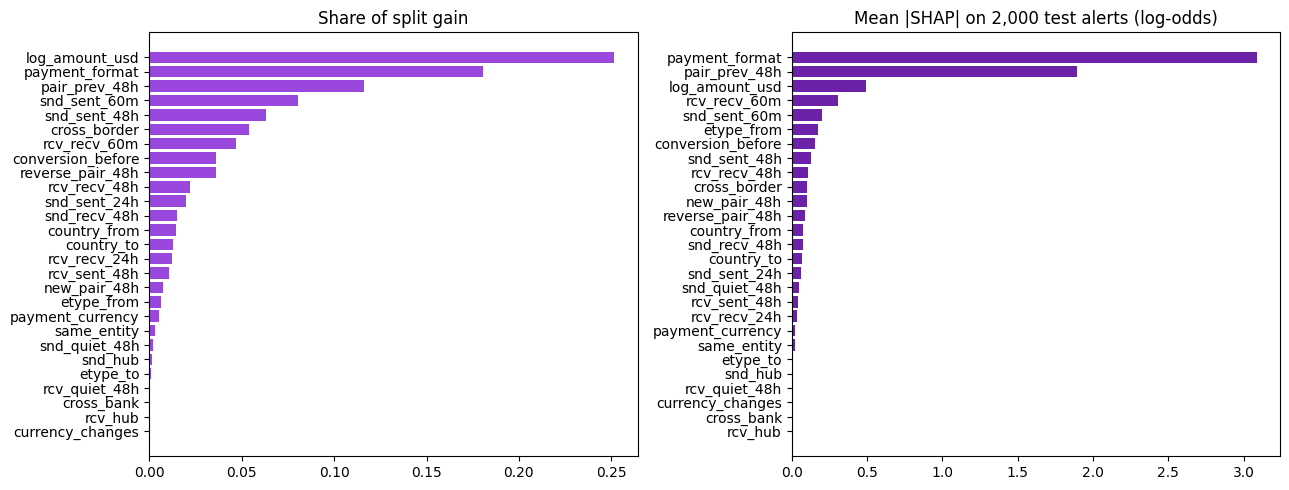

In [21]:
if hasattr(chosen, "importance"):
    imp = chosen.importance()
    alerted_idx = np.flatnonzero(alert)
    rng = np.random.default_rng(SEED)
    pick = rng.choice(alerted_idx, min(2000, len(alerted_idx)), replace=False) if len(alerted_idx) else []
    contrib = chosen.contributions(test.X.iloc[pick])
    shap_mean = contrib.drop(columns="bias").abs().mean().sort_values()

    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    g = imp.set_index("feature")["gain_share"].sort_values()
    axes[0].barh(g.index, g.values, color=PURPLE); axes[0].set_title("Share of split gain")
    axes[1].barh(shap_mean.index, shap_mean.values, color=DARK)
    axes[1].set_title(f"Mean |SHAP| on {len(pick):,} test alerts (log-odds)")
    plt.tight_layout(); plt.show()
elif hasattr(chosen, "pipeline"):
    display(M.logreg_coefficients(chosen).head(20))
else:
    print(f"rule model: score = {'+' if chosen.sign > 0 else '-'}{chosen.feature} - nothing else to show")

In [22]:
bundle_preview = {"model": chosen, "threshold": THRESHOLD}
examples = pd.concat([
    test.meta[alert & (test.y == 1)].head(2).assign(case="true alert"),
    test.meta[alert & (test.y == 0)].head(1).assign(case="false alert"),
])
scored = M.score_transactions(bundle_preview, test.X.loc[examples.index])
show = examples[["case", "Timestamp", "acct_from", "acct_to", "Payment Format", "amount_usd", "Pattern Type"]].join(scored)
with pd.option_context("display.max_colwidth", 200):
    display(show)

,case,Timestamp,acct_from,acct_to,Payment Format,amount_usd,Pattern Type,score,alert,reasons
0,true alert,2022-09-01 11:05:00,18196:80CAE3930,211:808E44B10,ACH,"5,669.09",GATHER-SCATTER,0.883767,True,"payment_format=ACH (+4.42), pair_prev_48h=0 (+2.33), conversion_before=1 (+1.49)"
1,true alert,2022-09-01 11:49:00,6179:809BBC7B0,211:808E44B10,ACH,"6,194.28",GATHER-SCATTER,0.905632,True,"payment_format=ACH (+4.58), pair_prev_48h=0 (+2.38), log_amount_usd=8.732 (+1.50)"
1764,false alert,2022-09-08 00:01:00,1665:8066D91E0,13145:8066D9320,ACH,"1,090.1",None,0.0455088,True,"payment_format=ACH (+3.24), pair_prev_48h=0 (+2.14), rcv_recv_60m=0 (+0.33)"


## <span style="color:#9947dc">13. Save for the agent layer</span>

**Why.** The agent's scoring tool loads one file and gets the model, the feature list and the
threshold, so it scores exactly as evaluated here.

**What is saved.**
- `models/txn_scorer.joblib` — model, threshold, budget, and provenance (feature folder, chosen
  settings, validation and test metrics). Load with `modeling.load_bundle`, score with
  `modeling.score_transactions(bundle, X)` → score, alert flag, top reasons.
- `models/test_scores.parquet` — `row_id`, score, alert for every test transfer, so the agent
  evaluation can start from the same alerts.
- `models/metrics.json` — the tables above, for the report.

In [23]:
MODELS_DIR.mkdir(exist_ok=True)
info = {
    "features_dir": str(FEATURES_DIR), "chosen": list(CHOSEN), "scale_pos_weight": str(BEST_SPW),
    "burn_in": BURN_IN, "train_neg_fraction": TRAIN_NEG_FRACTION, "seed": SEED,
    "feature_build": {k: report[k] for k in ("scored_rows", "lookback_hours", "split_days", "cutoff")},
    "val_pr_auc": float(val_table.query("model == @CHOSEN[0] and features == @CHOSEN[1]")["pr_auc"].iloc[0]),
    "test_pr_auc": float(test_table.query("model == @CHOSEN[0] and features == @CHOSEN[1]")["pr_auc"].iloc[0]),
}
M.save_bundle(MODELS_DIR / "txn_scorer.joblib", chosen, THRESHOLD, MAIN_BUDGET, info)

pd.DataFrame({"row_id": test.meta["row_id"], "score": s_test, "alert": alert}) \
  .to_parquet(MODELS_DIR / "test_scores.parquet", index=False)

def records(df):
    return json.loads(df.reset_index().to_json(orient="records", default_handler=str))
metrics = {"info": info, "overview": records(overview), "drift": records(drift),
           "single_feature": records(single), "spw": records(spw_table),
           "validation": records(val_table), "test": records(test_table),
           "test_budget": records(test_budget), "ci": records(ci_table),
           "scheme_summary": records(summary), "per_day": records(per_day)}
(MODELS_DIR / "metrics.json").write_text(json.dumps(metrics, indent=2, default=str))

# round-trip check: the saved bundle scores exactly like the in-memory model
b = M.load_bundle(MODELS_DIR / "txn_scorer.joblib")
assert np.allclose(b["model"].predict_score(test.X.head(1000)), s_test[:1000])
print("saved:", *[p.name for p in sorted(MODELS_DIR.iterdir())])

saved: metrics.json test_scores.parquet txn_scorer.joblib


## <span style="color:#9947dc">14. Findings</span>

*Fill in after running on the real data. Convention: every number written here must be visible
in an output above — copy, don't retype.*

| Question | Where to read it | Result |
|---|---|---|
| Does any feature drift between splits? | §3 `flag` column | |
| Best single feature and its lift | §4 first row | |
| Class weighting chosen | §6 table | |
| Model for the agent (val PR-AUC) | §7 last line | |
| Test PR-AUC vs prevalence, with 95% CI | §9 tables | |
| Precision / recall at the main budget, alerts per day | §9 budget table | |
| How much comes from generator artefacts (`all` vs `no_generator`) | §9 test table | |
| Recall on explained vs unexplained positives | §10 | |
| Complete test schemes with ≥ 1 alert | §11 | |
| Top features by gain / SHAP — consistent with EDA v2? | §12 | |

**Limitations to state in the report** (from the project state, still true here):
10 days of synthetic data — a structural hold-out, not a drift test; payment format and the
conversion step are generator mechanics; moved schemes put some pre-8-Sept rows in test; the
first 48 h are excluded from fitting because account-history windows are not full yet;
alerting the top X% assumes the alert volume a bank could staff, which we chose, not measured.